# Investigating river-level data across Scotland


**Emma Deyell, Gabriela Krawczyk & Saba Sitter**

# Setup

In [1]:
# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Clustering and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Supervised-learning 
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder

plt.rcParams.update({
    "figure.figsize": (7, 3),
    "font.size": 10,
    "figure.dpi": 150
})

In [2]:
# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

# Introduction

This report investigates river water levels in Scotland using observations from 392 river-level monitoring stations obtained from River Levels UK [1]. Three datasets contain daily minimum, mean and maximum water levels, while a fourth provides station locations. Coverage varies by station and date. The report tries to address two questions: (i) whether stations can be grouped according to their observed water-level behaviour and (ii) whether daily water levels can be predicted for September–November 2026, based on previous water-level measurements, using linear regression.

We first assess the quality and completeness of the datasets, remove unreliable observations and align the daily measurements across stations and dates. We then engineer features describing water-level variability and temporal behaviour of each station. These features provide a basis for investigating differences between monitoring stations and may also inform the regression analysis

(CHANGE THE LAST SENTENCE ONCE REGRESSION IS DONE - either to also inform the regrsssion analysis (no 'may inform') if they do or just delete this sentence? I said may as we haven't done it yet).

For clustering, we examine correlations between engineered features, select five complementary measures that avoid unnecessary redundancy, and compare K-means with several hierarchical linkage methods. We select Ward hierarchical clustering with five groups: four broad patterns of river-level behaviour and a small group of eight stations with exceptionally large within-day fluctuations. Although location was not used to form the clusters, their geographical distributions suggest an east–west association, with considerable overlap.

The second question was investigated using supervised machine learning techniques, with the modelling approach and evaluation methods determined by the selected prediction task. WRITE MORE ABOUT QUESTION 2

# Exploratory Data Analysis and Feature Engineering

## Exploratory Data Analysis


Invalid observations excluded: 79
Extreme outliers excluded (10 × IQR): 370
Dates excluded (>50% missing): 1094
Stations excluded (>10% missing): 63
Final dataset: 314 stations, 3293 dates


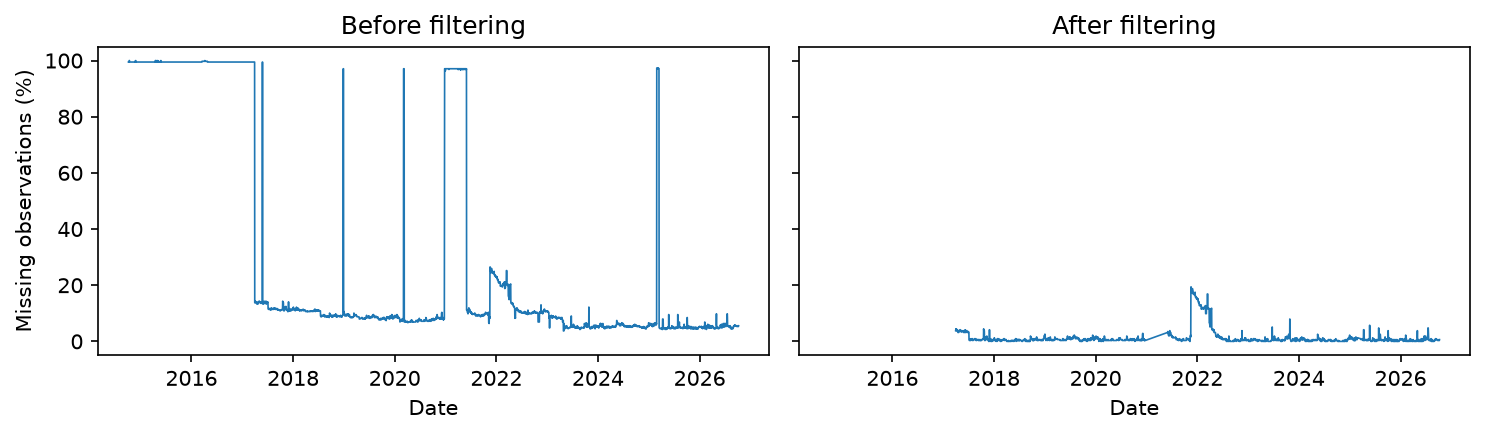

In [3]:
# Identify stations outside Scotland
stations_to_remove = df_locs.loc[
    df_locs["Station_Name"].str.strip().str.lower().isin(
        ["portrush", "bangor", "port erin"]),
    "Observation_ID"
].tolist()

# Identify stations with additional tidal observations
tidal_ids = df_locs.loc[
    df_locs["Observation_ID"].str.contains("tidal-level", case=False, na=False),
    "Observation_ID"
].tolist()

# Record those stations with separately labelled tidal observations
df_locs["Has_Tidal_Observation"] = (
    df_locs.groupby(["County", "Station_Name"])["Observation_ID"]
    .transform(lambda s: s.str.contains("tidal-level", case=False, na=False).any())
    .astype(int)
)

stations_to_remove += tidal_ids


def prepare_data(df):
    ''' Removes values we deem erroneous, as well as stations outside of Scotland and the tidal observations'''
    vals = df.iloc[:, 3:].copy()
    vals.columns = pd.to_datetime(vals.columns, dayfirst=True)
    vals.index = df["Observation_ID"]
    vals = vals.T.sort_index().asfreq("D")

    # Replace missing-value codes
    vals = vals.replace([999999.999, -999999.999, -99], np.nan)

    # Remove unwanted observation series
    vals = vals.drop(columns=stations_to_remove, errors="ignore")

    return vals


vals1 = prepare_data(df_avg)
vals2 = prepare_data(df_min)
vals3 = prepare_data(df_max)

# Check that all three datasets have identical stations and dates
assert vals1.index.equals(vals2.index) and vals1.index.equals(vals3.index)
assert vals1.columns.equals(vals2.columns) and vals1.columns.equals(vals3.columns)

# Identify invalid station-days across all three measurements
invalid = (
    (vals1.abs() > 100) |
    (vals2.abs() > 100) |
    (vals3.abs() > 100) |
    (vals2 > vals1) |
    (vals1 > vals3)
)

# Remove invalid observations before calculating outlier thresholds
vals1 = vals1.mask(invalid)
vals2 = vals2.mask(invalid)
vals3 = vals3.mask(invalid)

# Identify extreme outliers using station-specific IQR thresholds
Q1 = vals1.quantile(0.25)
Q3 = vals1.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    vals1.lt(Q1 - 10 * IQR, axis=1) |
    vals1.gt(Q3 + 10 * IQR, axis=1)
)

# Remove outlier station-days consistently from all datasets
vals1 = vals1.mask(outliers)
vals2 = vals2.mask(outliers)
vals3 = vals3.mask(outliers)

# Filter dates with more than 50% missing observations
good_dates = vals1.index[vals1.isna().mean(axis=1) <= 0.5]

# Filter stations with more than 10% missing observations
good_stations = vals1.loc[good_dates].columns[
    vals1.loc[good_dates].isna().mean(axis=0) <= 0.1
]

filtered_avg = vals1.loc[good_dates, good_stations].copy()
filtered_min = vals2.loc[good_dates, good_stations].copy()
filtered_max = vals3.loc[good_dates, good_stations].copy()

# Retain data for the remaining stations
df_locs_filtered = df_locs[
    df_locs["Observation_ID"].isin(good_stations)
].copy()

# Summarise data cleaning
print(f"Invalid observations excluded: {int(invalid.sum().sum())}")
print(f"Extreme outliers excluded (10 × IQR): {int(outliers.sum().sum())}")

print(f"Dates excluded (>50% missing): {len(vals1) - len(good_dates)}")
print(f"Stations excluded (>10% missing): {vals1.shape[1] - len(good_stations)}")

print(f"Final dataset: {filtered_avg.shape[1]} stations, {len(filtered_avg)} dates")


# Percentage of missing observations on each date
missing_before = vals1.isna().mean(axis=1) * 100
missing_after = filtered_avg.isna().mean(axis=1) * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharex=True, sharey=True)

for a, data, title in zip(
    ax,
    [missing_before, missing_after],
    ["Before filtering", "After filtering"]
):
    a.plot(data.index, data, linewidth=0.8)
    a.set(xlabel="Date", title=title)

ax[0].set_ylabel("Missing observations (%)")
plt.tight_layout()
plt.show()

*Figure 1: Percentage of missing data over time before and after filtering.*

### Data cleaning and preprocessing

River Levels UK states that its historical downloads contain raw, unchecked observations and may include errors [RIVER LEVELS UK], therefore the datasets were examined for missing, inconsistent and potentially erroneous observations before modelling. 

We identified three stations located outside Scotland (Portrush, Bangor and Port Erin), which were excluded from the analysis. Observations labelled as tidal-level were also removed to focus the clustering on river-level behaviour. Tidal water levels are measured relative to a different reference datum, making their fluctuations less directly comparable with those of inland rivers. Including these observations could therefore skew the clustering (AND REGRESSION MODEELING?). We have however retained information on stations with tidal observations in the location metadata, for later interpretation. We note that these are not necessarily the only rivers affected by tides, but rather those for which our data source provides separate tidal observation series.


The data were converted to a common daily time index, and the placeholder values `999999.999`, `-999999.999` and `-99` were treated as missing. We verified that the minimum, average and maximum datasets contained identical stations and dates. Measurements were then excluded where any absolute reading exceeded 100 m or where the expected relationship between daily measurements was violated (minimum ≤ average ≤ maximum). The 100 m threshold was chosen as a deliberately generous safeguard against implausible values.

Extreme outliers were identified using the distribution of daily average water levels at each station. We calculated the interquartile range (IQR), defined as the difference between the 75th and 25th percentiles, and excluded observations more than 10 IQRs below the 25th percentile or above the 75th percentile. This approach accounts for differences in typical water levels and variability between stations, while the generous threshold aims to remove only exceptionally large deviations and preserve most natural fluctuations. Although some genuine extreme high- or low-water events may have been excluded, we consider this a reasonable compromise between data quality and retaining meaningful variation. This decision was further supported by comparing several unusually high observations against the highest recorded levels reported by River Levels UK, which revealed discrepancies of several metres above the reported historical maxima. 

Whenever an observation was excluded, its corresponding minimum, average and maximum measurements were all treated as missing to maintain consistency.

Finally, dates with more than 50% missing average-level observations were removed, followed by stations with more than 10% missing observations across the retained dates. These thresholds balance data coverage against the need for sufficiently complete time series. 

This selection may favour stations with longer, more reliable records and may underrepresent locations with sparse observations. 

Figure 1 illustrates the distribution of missing observations before and after completeness filtering.

## Feature Engineering 

In [4]:
# Each row represents a station; columns are daily observations.
avg = filtered_avg.T.copy()
min_level = filtered_min.T.copy()
max_level = filtered_max.T.copy()

df_features = df_locs_filtered.set_index("Observation_ID").loc[avg.index].copy()

daily_range = max_level - min_level
daily_change = filtered_avg.asfreq("D").diff().T  # Only consecutive calendar days

# Within-day variation and variation over the observation period
df_features["Median_Daily_Range"] = daily_range.median(axis=1)
df_features["IQR_Level"] = avg.quantile(0.75, axis=1) - avg.quantile(0.25, axis=1)
df_features["Mean_Absolute_Daily_Change"] = daily_change.abs().mean(axis=1)

# Extreme rises relative to a common threshold across all stations
positive_change = daily_change.where(daily_change > 0)
rise_threshold = positive_change.stack().quantile(0.90)
df_features["Percent_Extreme_Rises"] = (
    daily_change.gt(rise_threshold).sum(axis=1)
    / daily_change.notna().sum(axis=1) * 100
)

# Compare typical daily rises and falls
mean_rise = positive_change.mean(axis=1)
mean_fall = -daily_change.where(daily_change < 0).mean(axis=1)
df_features["Rise_Fall_Asymmetry"] = mean_rise / mean_fall.replace(0, np.nan)

# Seasonal variation: difference between highest and lowest monthly median levels
monthly_medians = filtered_avg.groupby(filtered_avg.index.month).median().T
df_features["Seasonal_Amplitude"] = monthly_medians.max(axis=1) - monthly_medians.min(axis=1)

# Day-to-day persistence and variability of the within-day range
df_features["Daily_level_persistence"] = avg.apply(
    lambda row: row.asfreq("D").autocorr(lag=1),
    axis=1
)

df_features["Range_Variability"] = (
    daily_range.quantile(0.75, axis=1) -
    daily_range.quantile(0.25, axis=1)
)

feature_cols = [
    "Median_Daily_Range", "IQR_Level", "Mean_Absolute_Daily_Change",
    "Percent_Extreme_Rises", "Rise_Fall_Asymmetry", "Seasonal_Amplitude",
    "Daily_level_persistence", "Range_Variability"
]
feature_cols2 = [
    "Median_Daily_Range", "IQR_Level", "Mean_Absolute_Daily_Change",
    "Rise_Fall_Asymmetry", "Daily_level_persistence"
]

df_features = df_features.reset_index()
assert df_features[feature_cols].notna().all().all(), "Check missing engineered features"

The daily observations were used to create station-level features (Table 1 below). These measures describe different aspects of river-level behaviour rather than absolute water height, which depends on the local gauge reference level. 

| Feature | Description |
|---|---|
| Median daily range | Typical difference between daily maximum and minimum water levels |
| IQR of average level | Spread of the middle 50% of daily average levels |
| Mean absolute daily change | Typical magnitude of change in average level between consecutive days |
| Percentage of extreme rises | Percentage of days with a rise exceeding the 90th percentile of positive daily changes across all stations |
| Rise–fall asymmetry | Mean positive daily change divided by the magnitude of the mean negative daily change |
| Seasonal amplitude | Difference between the highest and lowest calendar-month median average levels |
| Daily level persistence | Measures how strongly a station's water level on one day is related to its water level on the previous day |
| Range variability | Interquartile range of daily maximum minus minimum water-level differences |

*Table 1: Features created from river-level data.*

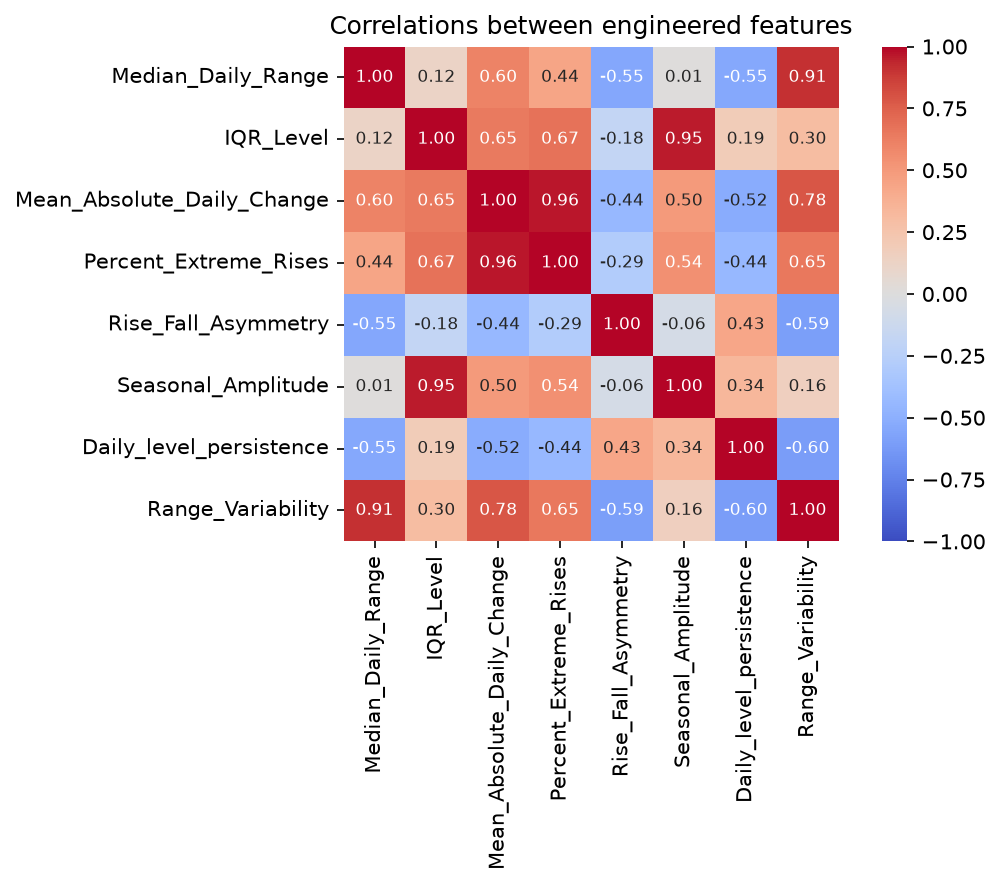

In [5]:
# Compare engineered features before choosing the final clustering inputs
df_visualise = df_features[feature_cols].copy()

plt.figure(figsize=(8, 6))
sns.heatmap(df_visualise.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 8})
plt.title("Correlations between engineered features")
plt.tight_layout()
plt.show()

*Figure 2: Correlation matrix of the engineered river-level features.*

The features in Table 1 were designed to distinguish stations with different types of water-level behaviour. Median daily range captures typical within-day fluctuations, while the IQR of average levels measures variability across the observation period. Mean absolute daily change describes the magnitude of day-to-day movements, rise–fall asymmetry distinguishes the typical sizes of rises and falls, and daily level persistence measures how strongly a day's level resembles the preceding day's level. Daily changes were calculated only between consecutive calendar days, so gaps were not mistaken for single-day changes.

The remaining three features were initially considered to capture additional aspects of station behaviour. However the correlation matrix (Figure 2) revealed strong relationships between several engineered features. In particular, percentage of extreme rises was highly correlated with mean absolute daily change (0.96), seasonal amplitude with IQR of average level (0.95), and variability of daily ranges with median daily range (0.91). This suggested that including all eight features could give overlapping aspects of river-level behaviour excessive influence in distance-based clustering.

After further investigating these relationships on a pairwise scatterplot of the features, we considered a reduced set of five features, excluding percentage of extreme rises, seasonal amplitude and variability of daily ranges. Mean absolute daily change was retained as a more general measure of day-to-day fluctuations, capturing both rises and falls rather than only unusually large rises. Similarly, IQR of average level was preferred as a measure of overall water-level variability that does not rely on seasonal patterns, while median daily range provides a straightforward measure of typical within-day fluctuations.

We explored clustering using both the original eight features and the reduced set of five to assess how feature selection influenced the results. The two approaches produced broadly similar patterns, although some differences in cluster assignments and group sizes were observed. We ultimately preferred the five-feature approach, as it reduced redundancy and allowed the clusters to be interpreted in terms of distinct aspects of river-level behaviour, without giving excessive weight to highly correlated measures. The five selected features: *median daily range, IQR of average level, mean absolute daily change, rise–fall asymmetry and daily level persistence*, were therefore used for the final clustering analysis. They capture within-day variability, longer-term variability, day-to-day changes, directional asymmetry and temporal dependence. All eight features remain available for other analyses. (DELETE THIS - all eight remain - IF WE DON'T USE THEM FOR ANY ANALYSIS IN REGRESSION).

## Clustering

### Model selection
We clustered stations using the five features selected above. As the variables have different scales, each was standardised to zero mean and unit variance before calculating Euclidean distances. We compared K-means with agglomerative hierarchical clustering using single, average, complete and Ward linkage. K-means provides a useful baseline based on compact groups around centroids. Hierarchical methods allow us to inspect how groups merge as the number of clusters decreases.

We assessed candidate solutions using silhouette coefficients, cluster sizes and whether the resulting groups represented meaningful differences in river behaviour.

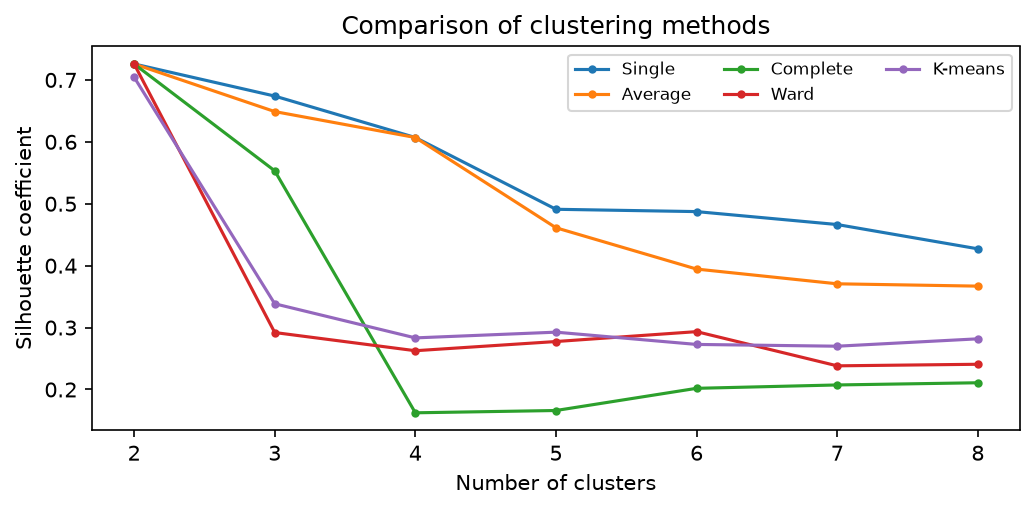


SINGLE
k=2: silhouette=0.726, sizes=[306, 8]
k=3: silhouette=0.674, sizes=[305, 8, 1]
k=4: silhouette=0.607, sizes=[304, 8, 1, 1]
k=5: silhouette=0.491, sizes=[303, 8, 1, 1, 1]
k=6: silhouette=0.487, sizes=[303, 7, 1, 1, 1, 1]

AVERAGE
k=2: silhouette=0.726, sizes=[306, 8]
k=3: silhouette=0.649, sizes=[304, 8, 2]
k=4: silhouette=0.607, sizes=[304, 8, 1, 1]
k=5: silhouette=0.461, sizes=[292, 12, 8, 1, 1]
k=6: silhouette=0.394, sizes=[286, 12, 8, 6, 1, 1]

COMPLETE
k=2: silhouette=0.726, sizes=[306, 8]
k=3: silhouette=0.553, sizes=[301, 8, 5]
k=4: silhouette=0.162, sizes=[182, 119, 8, 5]
k=5: silhouette=0.166, sizes=[182, 111, 8, 8, 5]
k=6: silhouette=0.202, sizes=[111, 108, 74, 8, 8, 5]

WARD
k=2: silhouette=0.726, sizes=[306, 8]
k=3: silhouette=0.292, sizes=[220, 86, 8]
k=4: silhouette=0.263, sizes=[111, 109, 86, 8]
k=5: silhouette=0.277, sizes=[111, 109, 71, 15, 8]
k=6: silhouette=0.293, sizes=[109, 99, 71, 15, 12, 8]


In [6]:
# Standardise the five selected station-level features
X_scaled = StandardScaler().fit_transform(df_features[feature_cols2])

# Compare hierarchical linkage methods and a K-means baseline
k_values = range(2, 9)
methods = ["single", "average", "complete", "ward"]
results = []
for method in methods:
    for k in k_values:
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_scaled)
        results.append({"Method": method.title(), "k": k,
                        "Silhouette": silhouette_score(X_scaled, labels),
                        "Smallest cluster": np.bincount(labels).min()})
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=0, n_init=20).fit_predict(X_scaled)
    results.append({"Method": "K-means", "k": k,
                    "Silhouette": silhouette_score(X_scaled, labels),
                    "Smallest cluster": np.bincount(labels).min()})
comparison = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(7, 3.5))
for method, group in comparison.groupby("Method", sort=False):
    ax.plot(group["k"], group["Silhouette"], marker="o", ms=3, label=method)
ax.set(xlabel="Number of clusters", ylabel="Silhouette coefficient",
       title="Comparison of clustering methods")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# Shows why high silhouettes can be misleading 
for method in methods:
    print(f"\n{method.upper()}")

    for k in range(2, 7):
        model = AgglomerativeClustering(
                n_clusters=k,
                linkage=method)

        labels = model.fit_predict(X_scaled)

        sizes = pd.Series(labels).value_counts().sort_values(ascending=False)
        score = silhouette_score(X_scaled, labels)

        print(f"k={k}: silhouette={score:.3f}, sizes={sizes.tolist()}")

*Figure 3: Silhouette coefficients for K-means and four hierarchical linkage methods across candidate cluster counts. The printed cluster sizes provide context for interpreting the scores.*

Figure 3 compares silhouette coefficients for K-means and four hierarchical linkage methods across 2–8 clusters. Higher scores generally indicate better cohesion and separation, but cluster sizes and interpretability are also important for our objective of identifying differences among Scottish rivers.

All methods achieved their highest silhouette scores with two clusters. Further inspection revealed that the methods consistently identified the same eight unusual stations, mostly as a separate cluster or rarely as part of a slightly larger group. These stations exhibited exceptionally large daily water-level ranges and low persistence, and all eight had a separately labelled tidal observation series. Their pronounced separation from the remaining stations contributes substantially to the high silhouette scores at two clusters. Further subdivisions distinguish stations whose behaviour is more similar, generally lowering silhouette scores without necessarily reducing the usefulness of the resulting groups.

Single and average linkage continued to achieve relatively high silhouette scores as the number of clusters increased. However, examination of the cluster sizes revealed that these methods tended to isolate individual stations while leaving almost all others in one large cluster. Complete linkage showed a similar tendency, although somewhat less extreme. For example, at four clusters, single and average linkage both produced groups of 304, 8, 1 and 1 stations, while complete linkage produced 291, 13, 8 and 2. These partitions offered limited differentiation among most Scottish rivers. We therefore considered them less suitable for the objectives of this project, despite their higher silhouette scores.

Ward linkage and K-means produced more balanced divisions of the remaining stations, making both more promising candidates. Their silhouette coefficients were broadly comparable, with neither method substantially outperforming the other across the cluster counts investigated. Consequently, silhouette analysis alone did not provide a convincing basis for choosing between them or determining the most appropriate number of clusters. We instead examined the resulting feature distributions, cluster sizes and interpretability of the groups. 

We ultimately preferred Ward hierarchical clustering. Unlike K-means, which assigns observations to clusters around centroids, Ward's method builds a hierarchy by successively merging groups while minimising increases in within-cluster variation. This was particularly useful for our dataset because it allowed us to examine how groups of stations were related and at what stage distinct behavioural patterns emerged. Both methods identified the most unusual stations, although K-means sometimes included additional stations in this group, reflecting differences in how the algorithms form clusters. Ward provided a more consistent separation of this group while allowing us to investigate further divisions among the remaining stations. Its dendrogram also offered an additional means of assessing the appropriate number of clusters. Although K-means remained a reasonable alternative, we considered the hierarchical approach better suited to our aim of exploring and interpreting relationships between river-level behaviours.

To investigate whether the separation of the eight unusual stations was obscuring meaningful differences among the remaining rivers, we explored a two-stage approach. After separating these eight stations, we re-standardised the features and applied Ward clustering to the remaining 306 stations. This allowed the scaling and silhouette assessment to focus on differences among the remaining stations. However, the resulting clustering identified another small group of just three stations, alongside two much larger groups of 166 and 137 stations. Although these three stations had relatively large daily ranges, their overall behaviour was less clearly distinct than that of the original eight, making this additional separation less informative for our objectives. Re-standardisation also alters the relative weighting of the features for the remaining clusters. We therefore preferred a single-stage Ward model fitted to all 314 stations, providing a simpler and more consistent framework for interpreting river-level behaviour.

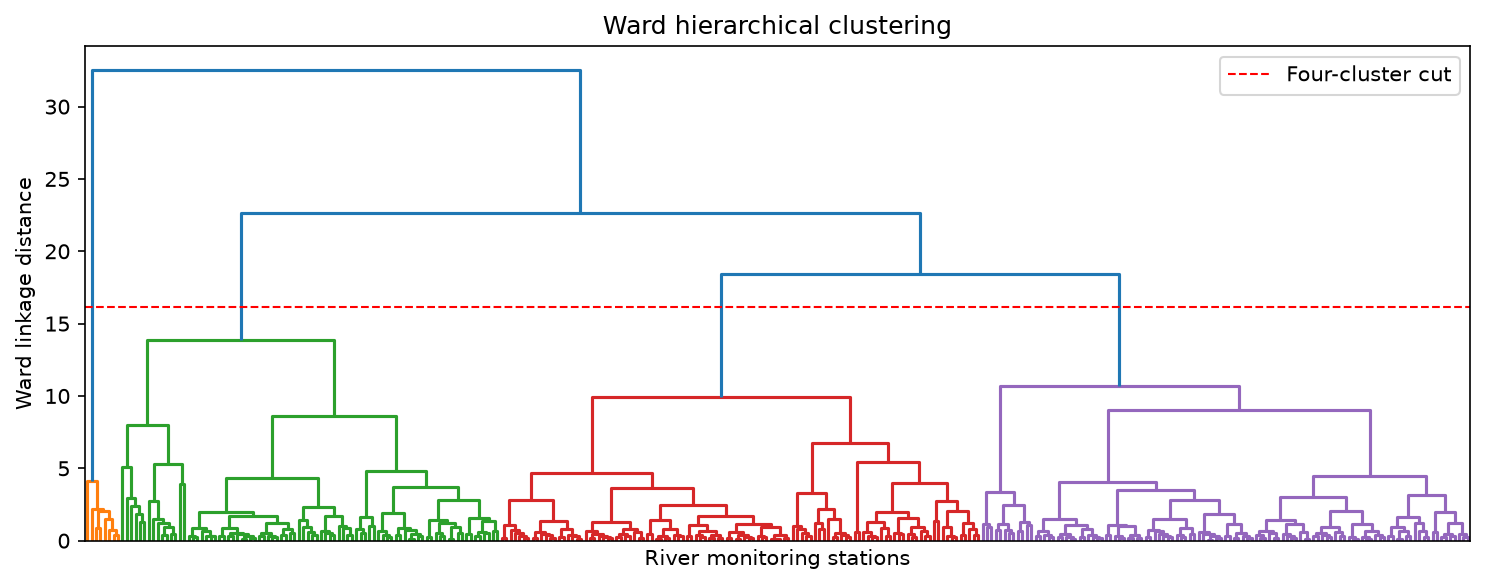

In [7]:
# Ward hierarchical clustering
Z = linkage(X_scaled, method="ward")

# Cut dendrogram into four clusters
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(10, 4))

dendrogram(
    Z,
    color_threshold=cut_height,
    no_labels=True,
    ax=ax
)

ax.axhline(
    cut_height,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Four-cluster cut"
)

ax.set(
    xlabel="River monitoring stations",
    ylabel="Ward linkage distance",
    title="Ward hierarchical clustering"
)

ax.legend()
plt.tight_layout()
plt.show()

# Final four-cluster solution
labels_all = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
).fit_predict(X_scaled)

df_features["Cluster"] = labels_all

*Figure 4: Ward dendrogram for the five standardised features. The heights show the dissimilarity at which groups merge.*

### Choosing the number of clusters
We investigated Ward solutions with three, four and five clusters, comparing the dendrogram, cluster sizes and differences in water-level characteristics. The three-cluster solution separated the eight unusual stations but divided the remaining stations into only two broad groups, providing limited differentiation of ordinary river-level behaviour.

Increasing to four clusters produced groups of 86, 109, 111 and 8 stations. The three larger groups exhibited distinguishable combinations of variability and persistence, allowing us to identify relatively stable stations, stations with greater day-to-day fluctuations, and stations with greater overall variability but stronger persistence.

The five-cluster solution further divided the 86-station group into groups of 71 and 15 stations, while leaving the other groups unchanged. The smaller group exhibited distinctive characteristics, including larger within-day ranges. However we decided that the additional subdivision offered a more detailed classification than was necessary, and it was less useful for our objective of identifying broad patterns of river-level behaviour.

The dendrogram also supported a four-cluster cut, although it did not establish a uniquely optimal number of clusters. We therefore selected four clusters as a balance between capturing meaningful variation and maintaining a relatively simple, interpretable classification. 



## Cluster characteristics

In [8]:
# Summarise the final clusters using original feature values
cluster_summary = (
    df_features.groupby("Cluster")[feature_cols2]
    .median()
    .T
)

# Add the number of stations in each cluster
cluster_summary.loc["Stations"] = (
    df_features["Cluster"].value_counts().sort_index()
)

# Put station counts first
cluster_summary = cluster_summary.loc[
    ["Stations"] + feature_cols2
]

# Display the table with readable labels and units
cluster_summary = cluster_summary.rename(index={
    "Median_Daily_Range": "Median daily range (m)",
    "IQR_Level": "IQR of average level (m)",
    "Mean_Absolute_Daily_Change": "Mean absolute daily change (m/day)",
    "Rise_Fall_Asymmetry": "Rise-fall asymmetry (ratio)",
    "Daily_level_persistence": "Daily level persistence (correlation)"
})

# Format station counts as integers and other values to 3 decimal places
formatted_summary = cluster_summary.copy().astype(object)

formatted_summary.loc["Stations"] = (
    cluster_summary.loc["Stations"].astype(int)
)

for col in formatted_summary.columns:
    for row in formatted_summary.index:
        if row != "Stations":
            formatted_summary.loc[row, col] = (
                f"{cluster_summary.loc[row, col]:.3f}"
            )

display(formatted_summary)

# Join the tidal observation flag to the final clusters
tidal_summary = df_features[["Observation_ID", "Cluster"]].merge(
    df_locs_filtered[
        ["Observation_ID", "Has_Tidal_Observation"]
    ],
    on="Observation_ID",
    how="left"
)

# Count stations with and without a separately labelled tidal series
tidal_counts = pd.crosstab(
    tidal_summary["Cluster"],
    tidal_summary["Has_Tidal_Observation"]
)

tidal_counts = tidal_counts.rename(columns={
    0: "No labelled tidal series",
    1: "Has labelled tidal series"
})

display(tidal_counts)

Cluster,0,1,2,3
Stations,86,109,111,8
Median daily range (m),0.063,0.050,0.020,2.865
IQR of average level (m),0.418,0.247,0.170,0.293
Mean absolute daily change (m/day),0.103,0.081,0.036,0.213
Rise-fall asymmetry (ratio),1.943,1.850,2.058,0.984
Daily level persistence (correlation),0.863,0.768,0.874,0.488


Has_Tidal_Observation,No labelled tidal series,Has labelled tidal series
Cluster,,
0,85,1
1,109,0
2,111,0
3,0,8


*Table 2: Cluster sizes and median values of the five water-level features for the final four-cluster Ward hierarchical clustering solution. Values are reported in their original units.*

*Table 3: Distribution of stations with and without separately labelled tidal observation series across the four clusters. Tidal observation status was not used as a clustering feature.*

### Cluster characteristics

The four clusters exhibit distinct patterns of water-level variability and temporal persistence, as summarised in Table 2.

**Cluster 0 (86 stations)** exhibits the greatest overall variability among the three larger groups, with a median daily range of 0.063 m, an IQR of average level of 0.418 m and a mean absolute daily change of 0.103 m/day. However, its relatively high daily level persistence (0.863) indicates a strong relationship between consecutive daily levels. This group therefore combines substantial water-level variation with relatively persistent day-to-day behaviour.

**Cluster 1 (109 stations)** exhibits intermediate variability, with a median daily range of 0.050 m and an IQR of average level of 0.247 m. Its persistence of 0.768 is the lowest among the three larger groups, suggesting less consistent levels between consecutive days. This distinguishes it from Cluster 0, which experiences greater overall variability but stronger persistence.

**Cluster 2 (111 stations)** represents the most stable group, with the smallest median daily range (0.020 m), IQR of average level (0.170 m) and mean absolute daily change (0.036 m/day). Its persistence of 0.874 is the highest among the three larger groups. These characteristics indicate relatively limited fluctuations and strongly correlated daily water levels.

**Cluster 3 (8 stations)** exhibits exceptionally large within-day fluctuations, with a median daily range of 2.865 m, compared with at most 0.063 m in the other clusters. It also has the lowest persistence (0.488) and a rise–fall asymmetry close to one (0.984), indicating similar average magnitudes of rises and falls. These characteristics are consistent with pronounced tidal influence.

As shown in Table 3, all eight stations in Cluster 3 have separately labelled tidal observation series, despite this information not being included among the clustering features. Of the nine retained stations with such observations, the exception is Lerwick, which belongs to Cluster 0. This suggests that Lerwick's overall water-level behaviour is more similar to that of Cluster 0. As the availability of a separately labelled tidal series is not a complete measure of tidal influence, other stations may also experience tidal effects. Cluster 3 is therefore best interpreted as a group exhibiting particularly pronounced tidal-like fluctuations, rather than an exhaustive classification of tidally influenced stations.

Overall, the clustering demonstrates that water-level behaviour is not determined by variability alone. In particular, Clusters 0 and 1 differ in their combination of variability and persistence, while Cluster 2 exhibits consistently lower fluctuations across the measured timescales.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 33.4 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 59.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 66.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [cartopy]m4/5 [cartopy]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/workspaces/MLP-PROJ/.venv/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/workspaces/MLP-PROJ/.venv/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/workspaces/MLP-PROJ/.venv/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


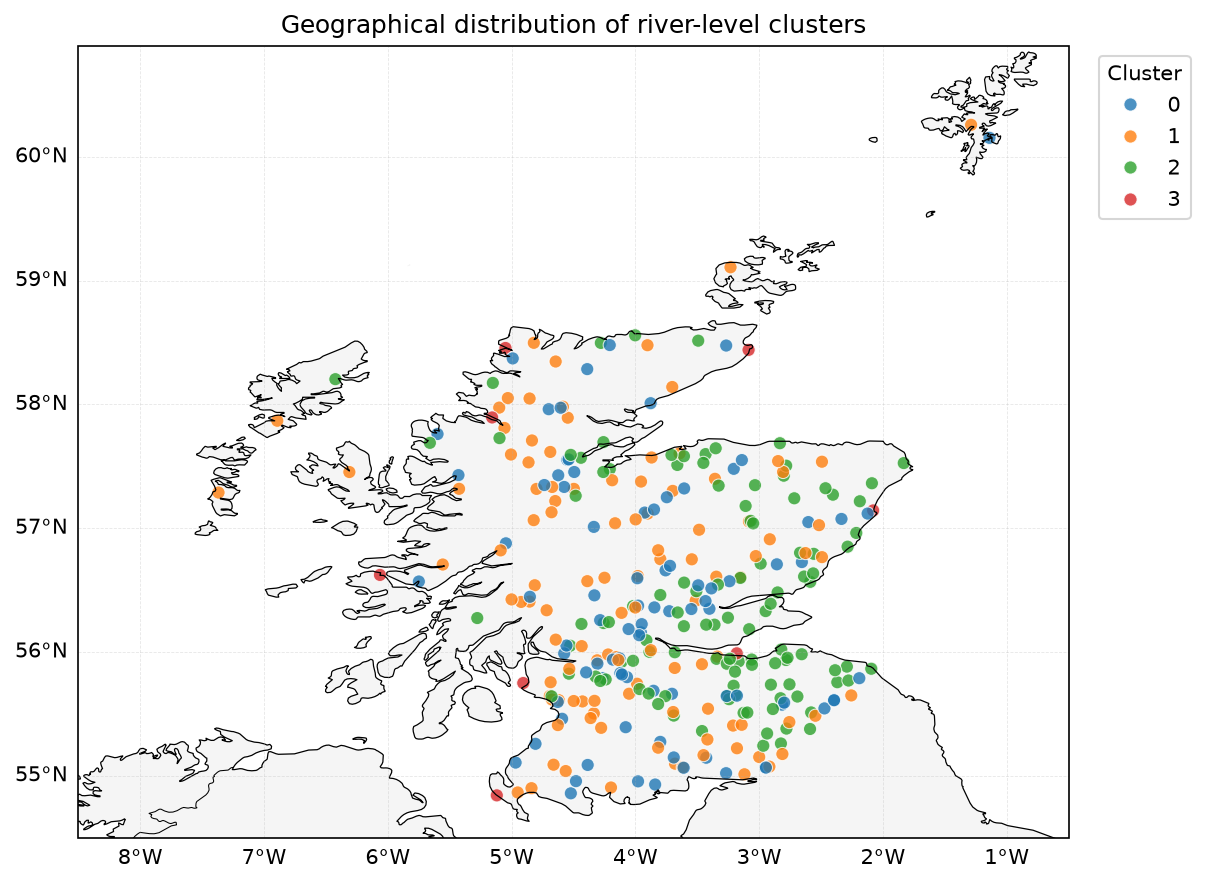

In [9]:
%pip install cartopy

import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, ax = plt.subplots(
    figsize=(8, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Simple geographical outline
ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Limit map to Scotland and its islands
ax.set_extent([-8.5, -0.5, 54.5, 60.9])

# Plot monitoring stations
sns.scatterplot(
    data=df_features,
    x="Longitude",
    y="Latitude",
    hue="Cluster",
    palette="tab10",
    s=40,
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    ax=ax
)

# Longitude and latitude labels
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.3,
    linestyle="--"
)
gl.top_labels = False
gl.right_labels = False

ax.set_title("Geographical distribution of river-level clusters")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1),
          loc="upper left")

plt.tight_layout()
plt.show()

*Figure 5. Geographical distribution of the four river-level clusters across Scotland.*

In [10]:
# Exclude the eight tidal-associated stations
df_geo = df_features[df_features["Cluster"] != 3].copy()

# Summarise geographical locations
geo_summary = df_geo.groupby("Cluster").agg(
    Stations=("Cluster", "size"),
    Median_longitude=("Longitude", "median"),
    Median_latitude=("Latitude", "median")
)

display(geo_summary.round(3))

,Stations,Median_longitude,Median_latitude
Cluster,,,
0,86,-3.953,56.339
1,109,-4.154,56.573
2,111,-3.238,56.227


*Table 4. Median geographical coordinates of the three larger river-level clusters, excluding the eight-station tidal-associated cluster.*

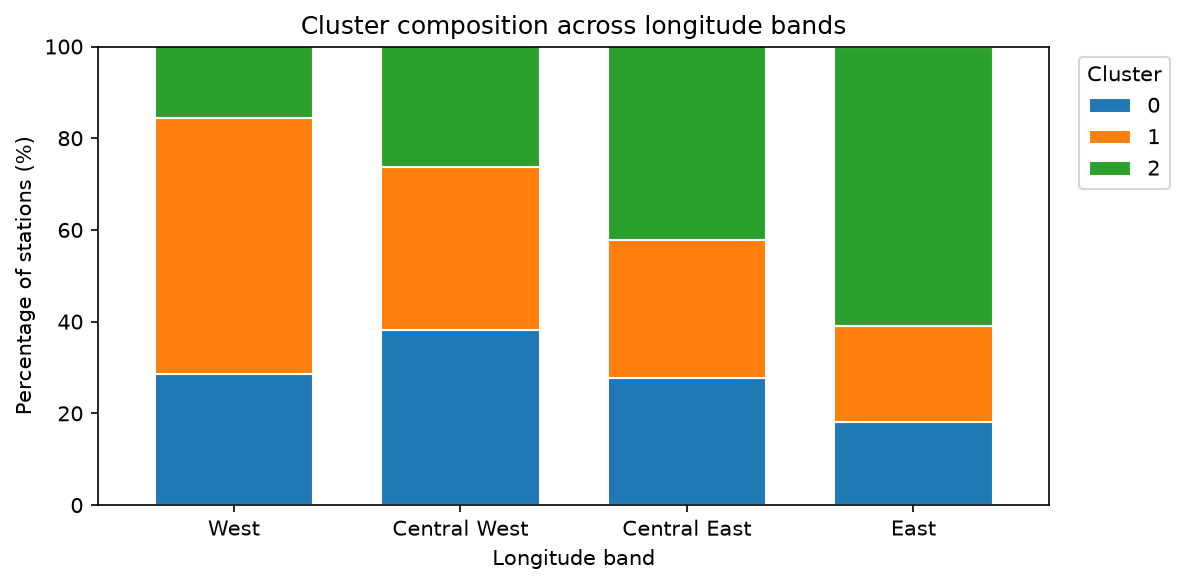

In [12]:
# Divide stations into four longitude bands
df_geo["Region"] = pd.qcut(
    df_geo["Longitude"],
    q=4,
    labels=["West", "Central West", "Central East", "East"]
)

# Count stations in each region and cluster
region_counts = pd.crosstab(
    df_geo["Region"],
    df_geo["Cluster"]
)

# Convert counts into percentages within each region
region_percent = region_counts.div(
    region_counts.sum(axis=1), axis=0
) * 100

# Plot stacked proportions
ax = region_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=sns.color_palette("tab10", 3),
    width=0.7,
    edgecolor="white"
)

ax.set(
    xlabel="Longitude band",
    ylabel="Percentage of stations (%)",
    title="Cluster composition across longitude bands",
    ylim=(0, 100)
)

ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1),
          loc="upper left")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

*Figure 6. Relative proportions of Clusters 0, 1 and 2 across four longitude bands defined by the quartiles of station longitude, excluding the tidal-associated cluster.*

### Geographical interpretation

Although geographical coordinates were not included among the clustering features, the resulting groups exhibited interesting spatial patterns. Figure 5 shows that the eight stations in Cluster 3 are distributed around coastal locations, consistent with their association with tidal observations. Given the small size and distinctive behaviour of this group, the subsequent geographical comparison focused on Clusters 0, 1 and 2.

Table 4 reveals greater differences between the median longitudes of the clusters than between their median latitudes. Cluster 2, characterised by low variability and high persistence, has the most easterly median longitude (−3.238°), while Cluster 1, characterised by intermediate variability and lower persistence, has the most westerly (−4.154°).

To investigate this relationship further, the stations were divided into four longitude bands using quartiles of their longitude distribution, ensuring approximately equal numbers of stations in each band. Figure 6 shows a clear east–west trend in cluster composition. The proportion of stations belonging to Cluster 2 increases consistently from about 15% in the westernmost band to around 60% in the easternmost band. On the other hand, the proportion belonging to Cluster 1 decreases from about 55% to 20%. Cluster 0 exhibits a less systematic geographical pattern, and seems to be similarly present everywhere.

### Discussion

The clustering analysis identified four groups of Scottish river-level monitoring stations, distinguished by their water-level variability and temporal behaviour. Three groups exhibited different combinations of within-day fluctuations, longer-term variability and daily persistence, while a fourth contained eight stations exhibiting exceptionally large within-day fluctuations associated with tidal observations.

A particularly interesting finding was the geographical distribution of the clusters. Despite geographical coordinates being excluded from the clustering process, a clear east–west trend emerged, which suggests an association between geographical location and river-level behaviour. 
The analysis showed that relatively stable river-level behaviour is more prevalent in eastern Scotland, while larger day-to-day fluctuations and lower persistence are more prevalent towards the west. Regional differences in rainfall, topography and catchment characteristics may contribute to this association however, these were not directly investigated, and the geographical distributions of the clusters overlapped substantially.

The identification of eight stations exhibiting pronounced tidal-like fluctuations also demonstrates the ability of unsupervised learning to identify distinctive behaviour without prior knowledge of station characteristics. 

From the perspective of the Scottish government, the clustering could provide a useful overview of differences in river-level behaviour across the monitoring network. Grouping stations with similar characteristics could support comparisons between monitoring locations, inform monitoring strategies and identify stations requiring further hydrological investigation. However, the clusters should not be interpreted directly as flood-risk categories, since water-level variability alone does not determine flood probability.

Several limitations should be considered:

- **Data quality:** The original datasets contained substantial missing and potentially erroneous observations. Although preprocessing improved data quality, completeness filtering may have introduced selection bias, while outlier removal may have excluded genuine extreme events.
- **Feature representation:** The engineered features summarise behaviour over the observation period and may conceal seasonal differences, changes over time and individual extreme events. Water-level measurements also do not directly describe river discharge or flood risk.
- **Clustering robustness:** The results depend on the selected features, their standardisation and the clustering method. During the work on the project we have found that a small correction to one feature calculation would produce noticeable changes in the assignment of some stations, despite having little effect on the feature correlation matrix. Nevertheless, the distinctive eight-station group remained intact. This suggests that the boundaries between the three larger clusters are less robust and should be interpreted as approximate behavioural categories rather than definitive classifications.

Further research could investigate the relationships between cluster membership and environmental variables such as rainfall, catchment area, elevation and land use. Independent information on tidal influence could also help validate the interpretation of Cluster 3. Additionally, examining whether cluster assignments remain consistent across different observation periods would provide a stronger assessment of the robustness of the classification.

### Conclusion

The clustering analysis successfully identified four interpretable groups of Scottish river-level monitoring stations, representing three broad patterns of water-level variability and persistence alongside a small group exhibiting pronounced tidal-like fluctuations.

A systematic east–west trend in cluster composition emerged despite geographical information being excluded from the clustering process. This highlights the potential of unsupervised learning to uncover meaningful patterns within large environmental datasets without relying on predefined geographical or hydrological classifications.

Overall, the analysis provides a useful framework for understanding differences in river-level behaviour across Scotland and identifying directions for further hydrological investigation. However, the overlap between clusters and the sensitivity of some assignments to feature calculations highlight the importance of interpreting the results alongside additional environmental information.

## Data Preparation for Supervised Learning

To evaluate the predictive performance of the supervised learning model, the dataset was divided into training and testing sets. Due to the time-dependent nature of river-level observations, the data were split chronologically rather than randomly. This prevented future observations from being used to predict historical water levels and make the forecasting more realistic.

The training dataset consisted of observations between 31/03/2017 and 31/08/2026. The forecasting period extended from 01/09/2026 to 30/11/2026, however, as recorded observations were only available until 08/10/2026, model performance could only be evaluated until then. 

Further feature engineering was undertaken to construct explanatory variables relevant to water-level prediction.

[EDIT TO ADD FEATURES AND JUSTIFICAITON ]

A sklearn pipeline was used to incorporate the necessary preprocessing steps into the model-fitting process, ensuring that any preprocessing requiring fitted parameters was based solely on the training data. The implementation of this pipeline is detailed in the Model Fitting and Tuning section.


Baseline MAE: 0.14695148609517564
Baseline RMSE: 0.2230487288453925
Observations evaluated: 12202


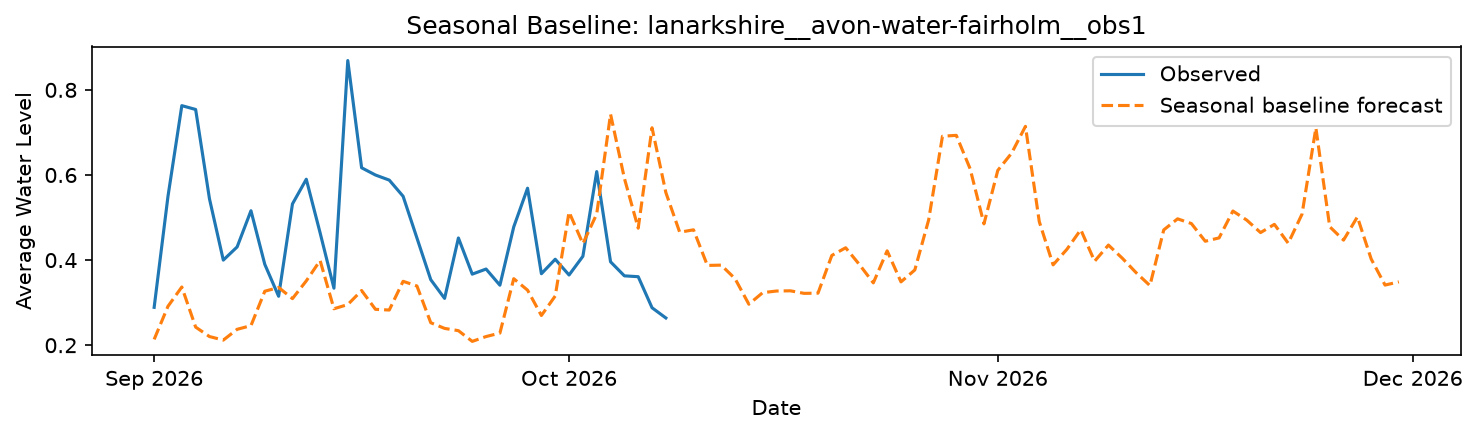

In [9]:
# Training data before September 2026
train_avg = filtered_avg.asfreq("D").loc[:"2026-08-31"]

# Forecast September-November 2026
forecast_dates = pd.date_range("2026-09-01", "2026-11-30")
baseline_forecast = pd.DataFrame(index=forecast_dates, columns=train_avg.columns, dtype=float)

# Equivalent dates from the previous six years
for date in forecast_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    baseline_forecast.loc[date] = train_avg.reindex(previous_dates).mean().values

# Evaluate predictions where observations are available
actual = filtered_avg.reindex(forecast_dates)
errors = actual - baseline_forecast

baseline_mae = errors.abs().stack().mean()
baseline_rmse = np.sqrt(errors.pow(2).stack().mean())

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Observations evaluated:", errors.notna().sum().sum())

# Plot predictions for a station
variation = baseline_forecast.std().dropna()
station = (variation - variation.median()).abs().idxmin()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(actual.index, actual[station], label="Observed")
ax.plot(baseline_forecast.index, baseline_forecast[station], "--", label="Seasonal baseline forecast")
ax.set(xlabel="Date", ylabel="Average Water Level", title=f"Seasonal Baseline: {station}")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
plt.tight_layout()
plt.show()

*Figure 6: Baseline model accuracy for one station.*

Training observations: 496901
Observations evaluated: 12202


,Model,MAE,RMSE
0,Seasonal Baseline,0.1470,0.2230
1,Linear Regression,0.1418,0.2109


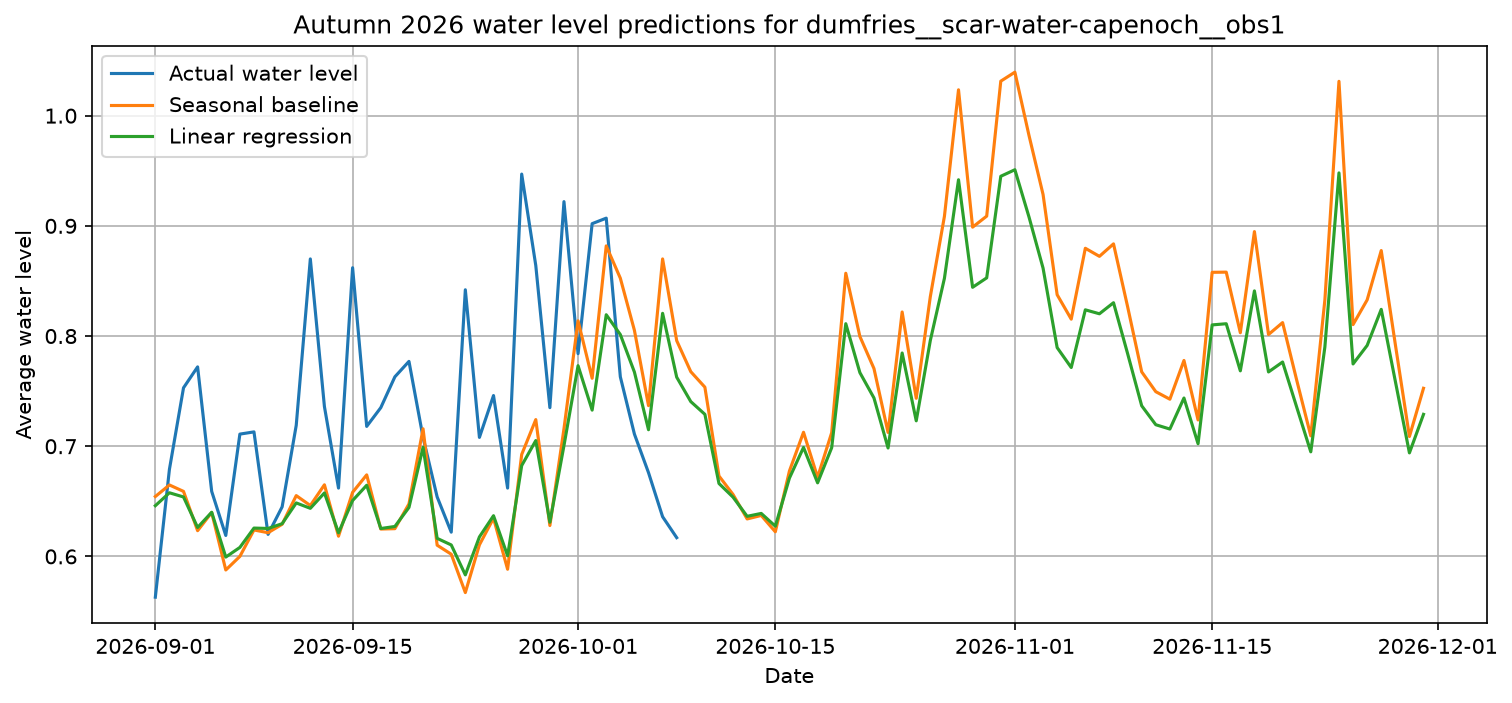

In [66]:

# Seasonal baseline model for autumn 2026
train_avg = filtered_avg.asfreq("D").loc[:"2026-08-31"]
forecast_dates = pd.date_range("2026-09-01", "2026-11-30")

baseline_forecast = pd.DataFrame(
    index=forecast_dates, columns=train_avg.columns, dtype=float
)

for date in forecast_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    baseline_forecast.loc[date] = train_avg.reindex(previous_dates).mean().values


# Use autumn 2020-2025 for training
train_dates = pd.date_range("2020-09-01", "2025-11-30")

# Calculate seasonal averages for training
historical_baseline = pd.DataFrame(
    index=train_dates, columns=train_avg.columns, dtype=float
)

for date in train_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    historical_baseline.loc[date] = train_avg.reindex(previous_dates).mean().values

# Calculate errors made by the seasonal baseline
historical_actual = train_avg.reindex(train_dates)
historical_errors = historical_actual - historical_baseline

# Prepare data for linear regression
train_data = historical_errors.stack().reset_index()
train_data.columns = ["Date", "Station", "Error"]

train_data["Seasonal_Average"] = [
    historical_baseline.loc[date, station]
    for date, station in zip(train_data["Date"], train_data["Station"])
]

# Add water level from the previous year
train_data["Previous_Year"] = [
    train_avg.loc[date - pd.DateOffset(years=1), station]
    for date, station in zip(train_data["Date"], train_data["Station"])
]

train_data = train_data.dropna()

# Define explanatory variables and target
X_train = train_data[["Seasonal_Average", "Previous_Year", "Station"]]
y_train = train_data["Error"]

# Scale numerical variables and encode station names
preprocessor = make_column_transformer(
    (StandardScaler(), ["Seasonal_Average", "Previous_Year"]),
    (OneHotEncoder(handle_unknown="ignore"), ["Station"])
)

# Fit linear regression model
pipe = make_pipeline(preprocessor, LinearRegression())
pipe.fit(X_train, y_train)


# Predict water levels for autumn 2026
forecast_data = baseline_forecast.stack().reset_index()
forecast_data.columns = ["Date", "Station", "Seasonal_Average"]

# Add water level from the previous year
forecast_data["Previous_Year"] = [
    train_avg.loc[date - pd.DateOffset(years=1), station]
    for date, station in zip(forecast_data["Date"], forecast_data["Station"])
]

# Replace missing previous year values with seasonal average
forecast_data["Previous_Year"] = forecast_data["Previous_Year"].fillna(
    forecast_data["Seasonal_Average"]
)

X_forecast = forecast_data[["Seasonal_Average", "Previous_Year", "Station"]]

# Predict corrections and add half to the seasonal baseline
forecast_data["Correction"] = pipe.predict(X_forecast)
forecast_data["Prediction"] = (
    forecast_data["Seasonal_Average"] + 0.5 * forecast_data["Correction"]
)

regression_2026 = forecast_data.pivot(
    index="Date", columns="Station", values="Prediction"
).reindex(index=forecast_dates, columns=train_avg.columns)


# Compare predictions with actual water levels
actual = filtered_avg.reindex(forecast_dates)

valid = (
    actual.notna()
    & baseline_forecast.notna()
    & regression_2026.notna()
)

comparison_2026 = pd.DataFrame({
    "Model": ["Seasonal Baseline", "Linear Regression"],
    "MAE": [
        (actual - p).where(valid).abs().stack().mean()
        for p in [baseline_forecast, regression_2026]
    ],
    "RMSE": [
        np.sqrt((actual - p).where(valid).pow(2).stack().mean())
        for p in [baseline_forecast, regression_2026]
    ]
})

print("Training observations:", len(X_train))
print("Observations evaluated:", valid.sum().sum())
display(comparison_2026.round(4))


# Plot actual and predicted water levels for one station
station = filtered_avg.columns[100]  

plt.figure(figsize=(12, 5))

plt.plot(actual.index, actual[station], label="Actual water level")
plt.plot(baseline_forecast.index, baseline_forecast[station], label="Seasonal baseline")
plt.plot(regression_2026.index, regression_2026[station], label="Linear regression")

plt.xlabel("Date")
plt.ylabel("Average water level")
plt.title(f"Autumn 2026 water level predictions for {station}")
plt.legend()
plt.grid(True)
plt.show()


# Model Fitting and Tuning

## Baseline Model

A seasonal baseline model was used to forecast daily average river water levels between September and November 2026. The approach was adapted from the equivalent-date forecasting method described in the Skforecast documentation $^2$.

For each forecasted date, the model calculated the mean water level recorded on the same day of the year over the previous six years, and used this to forecast the water level. This was performed independently for each monitoring station, producing forecasts for 91 days.

This method was selected because it provides a simple and interpretable baseline for evaluating more complex forecasting models. It allows predicted water levels to vary throughout the forecasting period according to historical seasonal behaviour, unlike a persistence model, which was also considered as a baseline. 

Model accuracy was assessed using mean absolute error (MAE) and root mean squared error (RMSE) for test dates where observations were available. Across 12,202 observations, the baseline had an MAE of 0.147 and an RMSE of 0.223. Figure 6 shows the seasonal baseline forecast for one monitoring station. The model captures variation in water level throughout the forecasting period, though differences are apparent, especially in September when water levels are underestimated. 

These results suggest that the seasonal baseline provides a reasonable benchmark for comparison with the final regression model, although it cannot account for sudden changes in water levels caused by unusual weather conditions.

# Interpretation, Discussion & Conclusions

The clustering analysis identified [XX] distinct groups of river monitoring stations across Scotland based on similarities in their water-level behaviour. The main distinguishing characteristics between these groups were [FEATURES].

The results of PCA suggested that two important aspects of river-level behaviour were the extent of general water-level variability and the magnitude and frequency of extreme fluctuations. The geographical distribution of the clusters also revealed [GEOGRAPHICAL FINDINGS].

One limitation of the analysis was the substantial proportion of missing observations in the original datasets. Although preprocessing reduced the percentage of missing observations from 30.61% to 1.33% in the average water-level dataset, approximately 25% of the original dates were removed. Consequently, the retained data may not be fully representative of river-level behaviour across the original time period.

Additionally, the engineered features were calculated across the retained time period, rather than accounting explicitly for seasonal variations in river-level behaviour. Monitoring stations exhibiting similar overall behaviour may behave differently at different times of the year.

The clustering results were also dependent on the choice of explanatory variables and clustering method. Further investigation into alternative feature sets and the stability of the resulting clusters could improve confidence in the findings.

This project investigated the application of supervised and unsupervised machine learning techniques to river-level monitoring data across Scotland.

The clustering analysis found that [MAIN CLUSTERING FINDINGS], whilst the supervised learning analysis demonstrated that [MAIN PREDICTION FINDINGS].

Together, these approaches demonstrate the potential for machine learning to improve understanding of river-level behaviour and support effective river management strategies across Scotland.

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

$^1$ https://riverlevels.uk/map
$^2$ https://skforecast.org/latest/user_guides/forecasting-baseline.html
$^3$ https://riverlevels.uk/pages/frequently-asked-questions


In [36]:
!jupyter nbconvert --to pdf project.ipynb --template=latex --template-file=compact.tex.j2

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files/
[NbConvertApp] Making directory ./project_files
[NbConvertApp] Writing 67590 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 583540 bytes to project.pdf
